# FoodSphere AI — Feature 1: Predicting leftovers before they happen

**Dataset:** Kaggle *Food Waste* dataset (8,000 daily inventory records, 2025). Raw file: `data/raw/food_waste_dataset.csv`.

**Goal:** in the **morning**, before the day starts, predict for a business + food category:
1. **How many units will be left over** (regression) → the app suggests a donation quantity.
2. **The waste risk level: Low / Medium / High** (classification) → accuracy, precision, recall, F1, confusion matrix.

Steps follow the preprocessing plan from the project notes, with two important fixes:
* **Data leakage check** added (columns only known at the end of the day are removed).
* **Split first**, then learn imputation / scaling / encoding statistics from the training data only.

In [1]:
import json, warnings, time
import numpy as np, pandas as pd
import matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import Image, display
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier, GradientBoostingRegressor
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report,
                             roc_auc_score, roc_curve, mean_absolute_error, mean_squared_error, r2_score, ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE
import pipeline as P
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid', palette=['#16804a', '#c97a0a', '#2f7fc4', '#7a5195', '#b42318'])
RS = 42
import os; os.makedirs('reports', exist_ok=True); os.makedirs('data/processed', exist_ok=True)
def save(fig, name):
    fig.tight_layout(); fig.savefig(f'reports/{name}.png', dpi=130); plt.close(fig); display(Image(f'reports/{name}.png'))

## 1. Data collection / loading

In [2]:
raw = P.load_raw()
print(raw.shape)
raw.head()

(8000, 16)


,Inventory_ID,Date,Business_Type,Food_Category,Purchase_Quantity,Units_Sold,Remaining_Stock,Shelf_Life_Days,Storage_Temperature,Daily_Demand,Promotion,Weather,Waste_Quantity,Waste_Reason,Donation_Made,Waste_Level
0,INV000001,2025-01-01,Restaurant,Bakery,77,77,0,4.0,20.4,77.0,No,Sunny,0,No Waste,No,Low
1,INV000002,2025-01-01,Cafeteria,Bakery,75,53,22,3.0,22.8,53.0,No,Cloudy,6,Low Demand,No,Medium
2,INV000003,2025-01-01,Supermarket,Fruits,176,159,17,6.0,12.4,159.0,No,Sunny,4,Expired,No,Medium
3,INV000004,2025-01-01,Cafeteria,Dairy,58,58,0,7.0,3.5,83.0,Yes,Cloudy,0,No Waste,No,Low
4,INV000005,2025-01-01,Restaurant,Fruits,85,85,0,3.0,3.3,87.0,No,Hot,0,No Waste,No,Low


In [3]:
dictionary = pd.read_csv('data/raw/data_dictionary.csv'); dictionary

,Column,Data_Type,Description,Approx_Missing_Pct
0,Inventory_ID,string,Unique identifier for each daily inventory rec...,NaN
1,Date,"string (date, YYYY-MM-DD)",Calendar date of the inventory record. Spans o...,NaN
2,Business_Type,categorical,"Type of business: Restaurant, Supermarket, Caf...",NaN
3,Food_Category,categorical,"Food category tracked: Fruits, Vegetables, Dai...",NaN
4,Purchase_Quantity,integer,Total units purchased/stocked for the day (uni...,NaN
5,Units_Sold,integer,Total units sold during the day (units). Alway...,NaN
6,Remaining_Stock,integer,Units left after sales (Purchase_Quantity - Un...,NaN
7,Shelf_Life_Days,float (integer-valued),"Number of days before the batch expires, depen...",~2.9%
8,Storage_Temperature,float,"Storage temperature in degrees Celsius, depend...",~2.3%
9,Daily_Demand,float (integer-valued),Estimated/realized customer demand for the day...,~2.6%


## 2. Exploratory data analysis (EDA) — *added step*
Look before cleaning: types, missing values, duplicates, distributions and target balance.

In [4]:
info = pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum(), 'missing_%': (raw.isna().mean()*100).round(2), 'unique': raw.nunique()})
info

,dtype,missing,missing_%,unique
Inventory_ID,str,0,0.00,8000
Date,str,0,0.00,365
Business_Type,str,0,0.00,4
Food_Category,str,0,0.00,6
Purchase_Quantity,int64,0,0.00,296
Units_Sold,int64,0,0.00,213
Remaining_Stock,int64,0,0.00,204
Shelf_Life_Days,float64,235,2.94,14
Storage_Temperature,float64,186,2.33,367
Daily_Demand,float64,210,2.62,250


In [5]:
print('Duplicate rows:', raw.duplicated().sum(), '| Duplicate IDs:', raw['Inventory_ID'].duplicated().sum())
raw.describe().T.round(2)

Duplicate rows: 0 | Duplicate IDs: 0


,count,mean,std,min,25%,50%,75%,max
Purchase_Quantity,8000.0,118.29,58.69,35.0,80.0,104.0,148.0,968.0
Units_Sold,8000.0,96.96,39.28,26.0,67.0,87.0,121.0,284.0
Remaining_Stock,8000.0,21.33,41.66,0.0,0.0,9.0,30.0,858.0
Shelf_Life_Days,7765.0,4.36,2.60,1.0,2.0,4.0,6.0,14.0
Storage_Temperature,7814.0,10.45,8.43,-4.4,3.7,7.5,18.1,36.6
Daily_Demand,7790.0,105.10,45.16,26.0,71.0,94.0,132.0,316.0
Waste_Quantity,8000.0,5.77,16.45,0.0,0.0,1.0,7.0,447.0


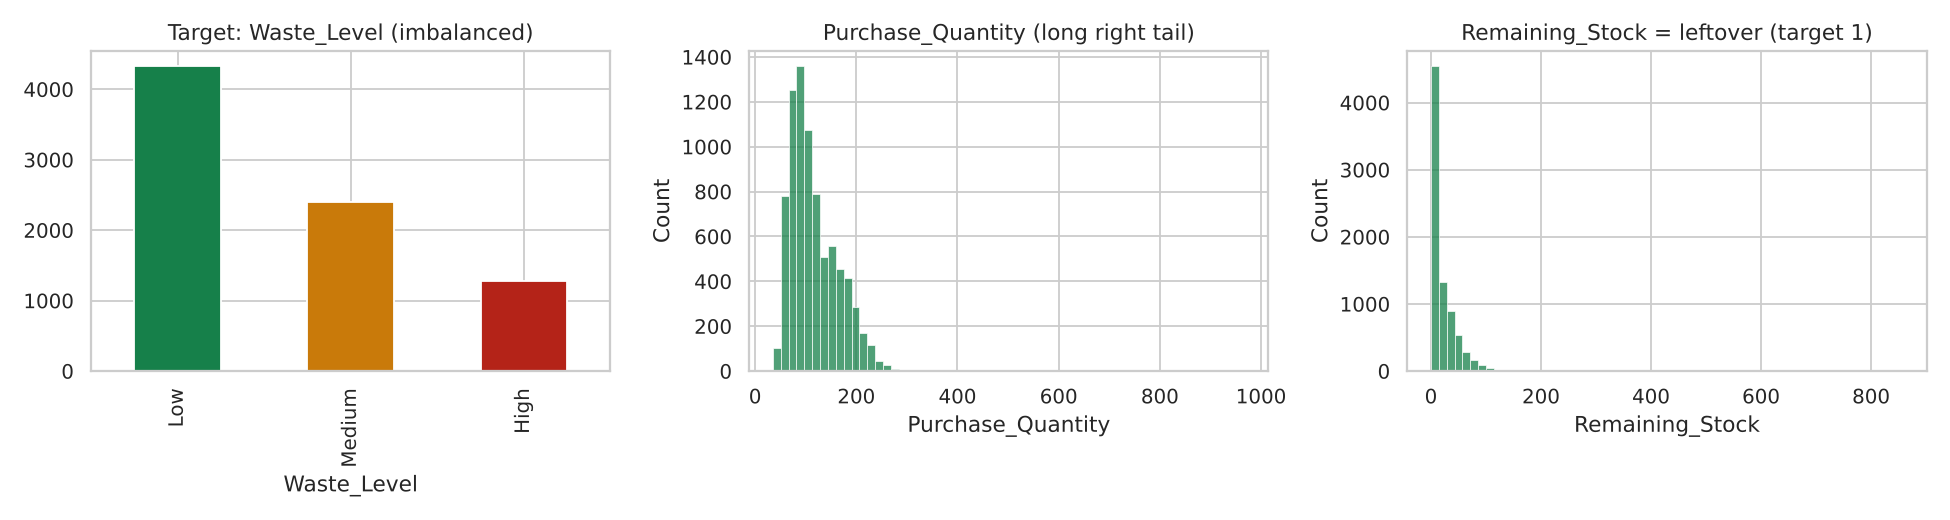

Waste_Level
Low       54.1
Medium    30.0
High      15.9
Name: proportion, dtype: float64


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
raw['Waste_Level'].value_counts().reindex(P.WASTE_LEVELS).plot.bar(ax=ax[0], color=['#16804a', '#c97a0a', '#b42318']); ax[0].set_title('Target: Waste_Level (imbalanced)')
sns.histplot(raw['Purchase_Quantity'], bins=60, ax=ax[1]); ax[1].set_title('Purchase_Quantity (long right tail)')
sns.histplot(raw['Remaining_Stock'], bins=60, ax=ax[2]); ax[2].set_title('Remaining_Stock = leftover (target 1)')
save(fig, 'eda_distributions')
print((raw['Waste_Level'].value_counts(normalize=True)*100).round(1))

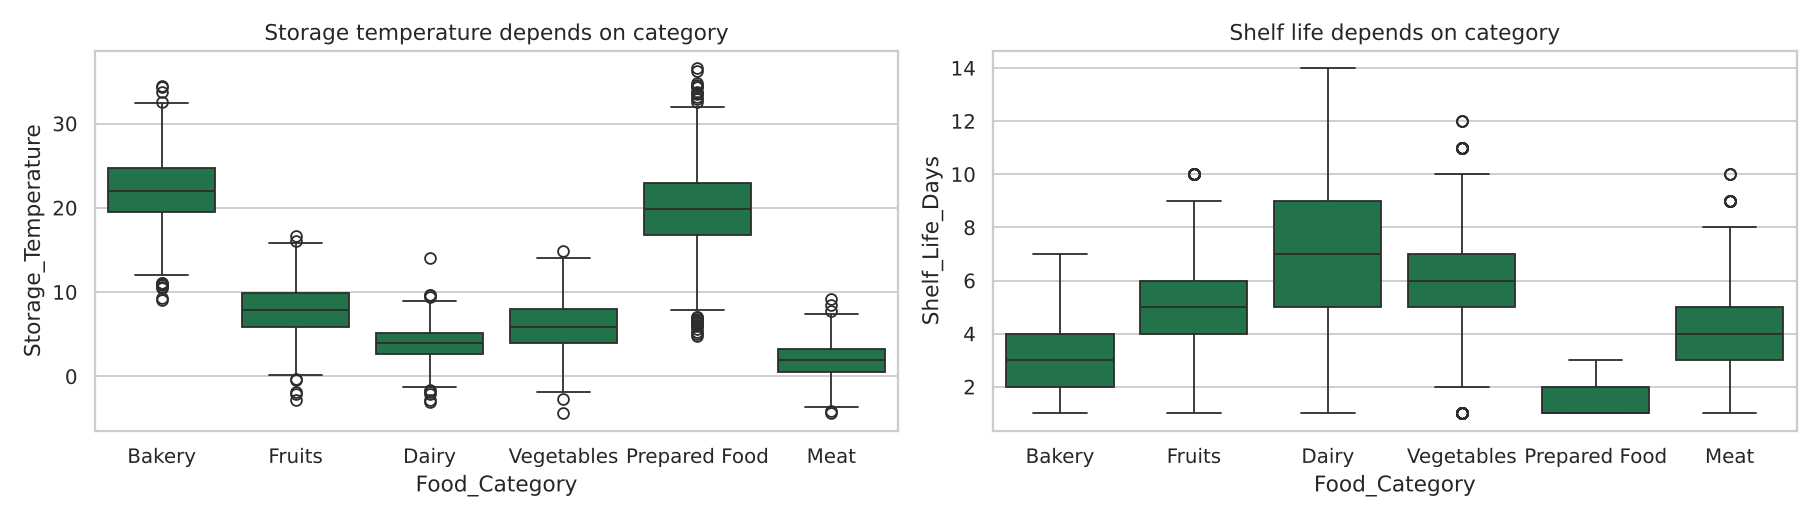

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(data=raw, x='Food_Category', y='Storage_Temperature', ax=ax[0]); ax[0].set_title('Storage temperature depends on category')
sns.boxplot(data=raw, x='Food_Category', y='Shelf_Life_Days', ax=ax[1]); ax[1].set_title('Shelf life depends on category')
save(fig, 'eda_by_category')

## 3. Data-leakage check — *added step (most important)*
The app predicts **in the morning**. Some columns are only known **at the end of the day**. If the model sees them it can
"cheat" and score ~100% in testing but be useless in real life. Proof from the data:

In [8]:
d = raw.dropna(subset=['Daily_Demand'])
print('Remaining_Stock == Purchase - Units_Sold :', (raw.Remaining_Stock == raw.Purchase_Quantity - raw.Units_Sold).mean())
print('Units_Sold == min(Purchase, Daily_Demand):', (d.Units_Sold == np.minimum(d.Purchase_Quantity, d.Daily_Demand)).mean())
print('Waste_Reason == "No Waste"  <=>  Waste_Quantity == 0 :', ((raw.Waste_Reason == 'No Waste') == (raw.Waste_Quantity == 0)).mean())
print('Columns removed from model inputs:', P.LEAKAGE_COLUMNS)

Remaining_Stock == Purchase - Units_Sold : 1.0
Units_Sold == min(Purchase, Daily_Demand): 1.0
Waste_Reason == "No Waste"  <=>  Waste_Quantity == 0 : 1.0
Columns removed from model inputs: ['Units_Sold', 'Remaining_Stock', 'Daily_Demand', 'Waste_Quantity', 'Waste_Reason', 'Donation_Made']


Daily_Demand is the realised demand of that day, so it is only used (a) to build the training target and (b) to compute **historical averages from past days**, never the same day's value.

## 4. Data cleaning
Type conversion (dates, Yes/No → 1/0), text trimming, duplicate removal, business-rule validation, drop the ID column.

In [9]:
df, clean_report = P.clean(raw)
print(json.dumps(clean_report, indent=2))
df.dtypes

{
  "rows_in": 8000,
  "invalid_dates": 0,
  "duplicate_ids": 0,
  "duplicate_records": 0,
  "rule_violations_removed": 0,
  "rows_out": 8000
}


Date                   datetime64[us]
Business_Type                  string
Food_Category                  string
Purchase_Quantity               int64
Units_Sold                      int64
Remaining_Stock                 int64
Shelf_Life_Days               float64
Storage_Temperature           float64
Daily_Demand                  float64
Promotion                       int64
Weather                        string
Waste_Quantity                  int64
Waste_Reason                   string
Donation_Made                 float64
Waste_Level                    string
dtype: object

## 5. Handle missing data & duplicates
**Duplicates:** none found (checked by ID and by full record). **Missing values** (2–3% in five columns):

In [10]:
miss = df.isna().sum(); miss[miss > 0]

Shelf_Life_Days        235
Storage_Temperature    186
Daily_Demand           210
Weather                203
Donation_Made          233
dtype: int64

| Column | Strategy | Why |
|---|---|---|
| Shelf_Life_Days | median **per food category** | shelf life depends on the category |
| Storage_Temperature | median **per food category** | temperature depends on the category |
| Weather | most frequent value | categorical, few missing |
| Daily_Demand | **logical recovery**: if stock was left over, demand = units sold exactly | follows from Units_Sold = min(Purchase, Demand) |
| Donation_Made | not used (leakage column) | — |

The medians / mode are learned **after splitting, from the training data only** (step 7).

In [11]:
dem = P.recover_demand(df)
print('Daily_Demand missing before:', df.Daily_Demand.isna().sum(), '-> after logical recovery:', dem.isna().sum(),
      '(rows still missing were sold out, so true demand is unknown; they are skipped only when training the demand model)')

Daily_Demand missing before: 210 -> after logical recovery: 63 (rows still missing were sold out, so true demand is unknown; they are skipped only when training the demand model)


## 6. Handle outliers

In [12]:
q1, q3 = df.Purchase_Quantity.quantile([.25, .75]); iqr = q3 - q1
out = df[df.Purchase_Quantity > q3 + 3 * iqr]
print(f'Extreme purchases (> Q3 + 3·IQR = {q3 + 3*iqr:.0f}):', len(out))
out[['Date', 'Business_Type', 'Food_Category', 'Purchase_Quantity', 'Units_Sold', 'Remaining_Stock', 'Waste_Level']].head(8)

Extreme purchases (> Q3 + 3·IQR = 352): 44


,Date,Business_Type,Food_Category,Purchase_Quantity,Units_Sold,Remaining_Stock,Waste_Level
146,2025-01-07,Supermarket,Fruits,592,254,338,High
222,2025-01-11,Supermarket,Meat,968,110,858,High
402,2025-01-18,Supermarket,Bakery,664,117,547,High
713,2025-02-02,Supermarket,Vegetables,397,116,281,High
1599,2025-03-12,Restaurant,Prepared Food,450,97,353,High
1658,2025-03-15,Restaurant,Vegetables,577,99,478,High
1873,2025-03-25,Supermarket,Dairy,595,176,419,High
1913,2025-03-27,Supermarket,Prepared Food,703,204,499,High


These are **real over-stock events** (huge purchase, normal sales → large leftover, mostly *High* waste).
They are exactly what we want the model to catch, so they are **kept**, not deleted.
For distance/linear models their influence is reduced with a log transform (`Purchase_Log`) and standard scaling;
tree models are not affected by outliers.

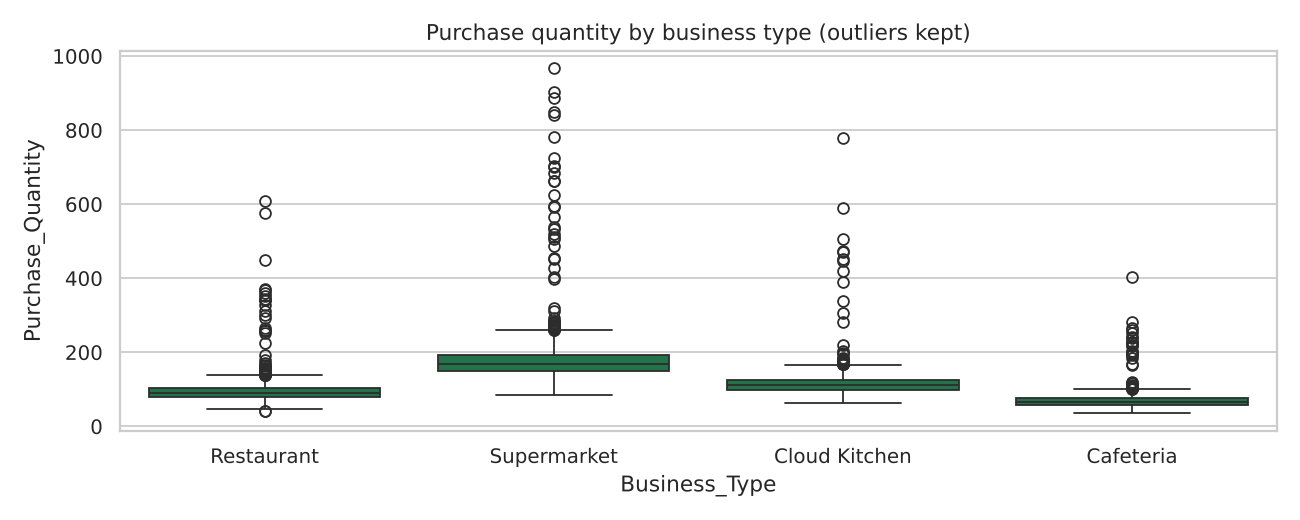

In [13]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=df, x='Business_Type', y='Purchase_Quantity', ax=ax); ax.set_title('Purchase quantity by business type (outliers kept)')
save(fig, 'outliers_purchase')

## 7. Data splitting — *moved before encoding/scaling*
Chronological split (70% / 15% / 15%) so the model is always tested on **later dates** than it learned from — like real use.

In [14]:
train, val, test = P.chronological_split(df)
for n, s in [('train', train), ('validation', val), ('test', test)]:
    print(f'{n:<11} {len(s):>5} rows  {s.Date.min().date()} → {s.Date.max().date()}  | High waste: {(s.Waste_Level=="High").mean():.1%}')
artifacts = P.fit_artifacts(train)   # medians, mode and historical averages — TRAINING DATA ONLY
print('Category medians (shelf life):', artifacts['shelf_life_median'])

train        5612 rows  2025-01-01 → 2025-09-12  | High waste: 15.4%
validation   1203 rows  2025-09-13 → 2025-11-06  | High waste: 17.7%
test         1185 rows  2025-11-07 → 2025-12-31  | High waste: 16.3%


Category medians (shelf life): {'Bakery': 3.0, 'Dairy': 7.0, 'Fruits': 5.0, 'Meat': 4.0, 'Prepared Food': 1.0, 'Vegetables': 6.0}


## 8. Feature engineering / creation
| Feature | Meaning |
|---|---|
| Day_Of_Week, Is_Weekend (Fri/Sat), Month, Season | calendar effects (Bangladesh seasons) |
| Purchase_Log | log of purchase (reduces outlier influence) |
| Temp_Deviation | storage temperature minus the category’s normal temperature (storage-problem signal) |
| **Expected_Demand** | historical average demand for this business type + category + promotion + weather (from training days only) |
| **Expected_Leftover** | max(0, purchase − expected demand) |
| **Overstock_Ratio** | purchase ÷ expected demand |
| Leftover_Ratio_Exp | expected leftover ÷ purchase |
| **Spoil_Rate_Est** | share of leftovers that usually spoil, learned from past days by category × shelf life, storage temperature and weather |
| **Waste_Ratio_Est** | expected leftover share × spoil rate — the morning estimate of the share of food that will be wasted (the waste level is defined by this share) |
| Waste_Units_Est, Inv_Shelf_Life | expected wasted units; 1 ÷ shelf life |

In [15]:
Xtr, Xva, Xte = (P.build_features(s, artifacts) for s in (train, val, test))
print('Features:', Xtr.shape[1]); Xtr.head(3).T.head(16)

Features: 35


,0,1,2
Purchase_Quantity,77.000000,118.000000,81.000000
Purchase_Log,4.356709,4.779123,4.406719
Shelf_Life_Days,4.000000,4.000000,6.000000
Storage_Temperature,20.400000,1.900000,5.700000
Temp_Deviation,-1.900000,0.000000,-0.400000
Promotion,0.000000,0.000000,0.000000
Day_Of_Week,2.000000,2.000000,2.000000
Is_Weekend,0.000000,0.000000,0.000000
Month,1.000000,1.000000,1.000000
Expected_Demand,85.075800,106.408200,106.240700


## 9. Encoding categorical variables
**One-hot encoding** for Business_Type, Food_Category, Weather and Season (no artificial order between categories). Promotion is binary (Yes → 1, No → 0). Label encoding is used only for the target (Low/Medium/High).

In [16]:
print([c for c in Xtr.columns if '=' in c])

['Business_Type=Cafeteria', 'Business_Type=Cloud Kitchen', 'Business_Type=Restaurant', 'Business_Type=Supermarket', 'Food_Category=Bakery', 'Food_Category=Dairy', 'Food_Category=Fruits', 'Food_Category=Meat', 'Food_Category=Prepared Food', 'Food_Category=Vegetables', 'Weather=Cloudy', 'Weather=Hot', 'Weather=Rainy', 'Weather=Sunny', 'Season=Winter', 'Season=Summer', 'Season=Monsoon', 'Season=Autumn']


## 10. Feature scaling / normalisation
**Z-score standardisation** (StandardScaler), fitted on training data only. Applied **only** to models that need it (Logistic/Linear Regression, KNN). Tree models do not need scaling.

In [17]:
sc = StandardScaler().fit(Xtr)
pd.DataFrame({'mean (train)': sc.mean_.round(2), 'std (train)': sc.scale_.round(2)}, index=Xtr.columns).head(8)

,mean (train),std (train)
Purchase_Quantity,117.60,57.16
Purchase_Log,4.69,0.40
Shelf_Life_Days,4.36,2.59
Storage_Temperature,10.50,8.44
Temp_Deviation,-0.01,3.35
Promotion,0.20,0.40
Day_Of_Week,3.01,1.98
Is_Weekend,0.29,0.45


## 11. Feature selection
Mutual information between each feature and the waste level (training data). In the first version, features with ~zero information were dropped. The rolling time-series check in step 14 showed that dropping them gives **no** accuracy gain (tree models ignore weak features themselves), so **all features are kept**; the chart still shows which features carry the most information.

Low-information features (kept, trees ignore them): ['Season=Winter', 'Season=Summer', 'Season=Monsoon', 'Season=Autumn']


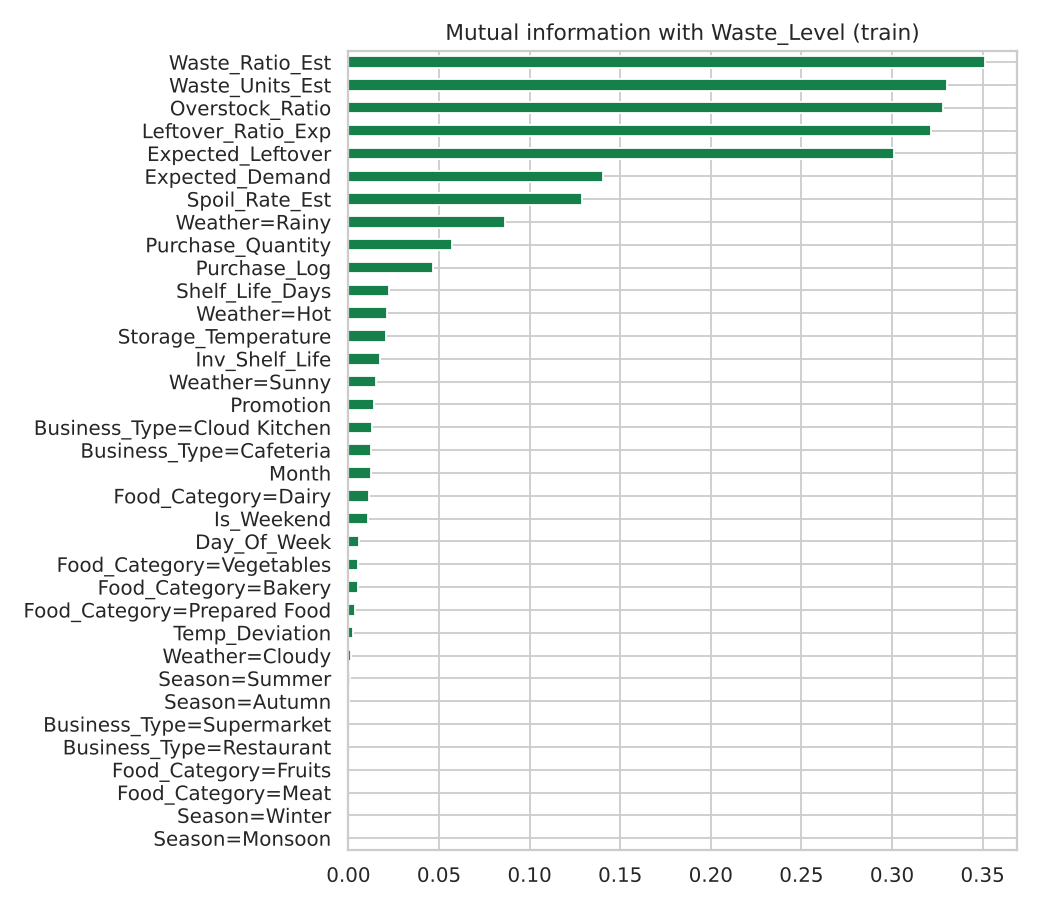

In [18]:
y_tr, y_va, y_te = train.Waste_Level.values, val.Waste_Level.values, test.Waste_Level.values
mi = pd.Series(mutual_info_classif(Xtr, y_tr, random_state=RS), index=Xtr.columns).sort_values(ascending=False)
groups = {}
for c in Xtr.columns: groups.setdefault(c.split('=')[0], []).append(c)
keep = [c for g, cols in groups.items() if mi[cols].max() > 0.002 for c in cols]
print('Low-information features (kept, trees ignore them):', [c for c in Xtr.columns if c not in keep] or 'none')
fig, ax = plt.subplots(figsize=(8, 7)); mi.plot.barh(ax=ax, color='#16804a'); ax.invert_yaxis(); ax.set_title('Mutual information with Waste_Level (train)')
save(fig, 'feature_mutual_information')
FEATURES = list(Xtr.columns)
Xtr, Xva, Xte = Xtr[FEATURES], Xva[FEATURES], Xte[FEATURES]

## 12. Handling imbalanced data
Only 16% of records are *High*. We compare three strategies: no balancing, class weights and SMOTE oversampling.

**Goal (version 2): overall accuracy.** Version 1 chose SMOTE because it finds more *High* days, but it costs accuracy. Version 2 is judged on **accuracy over 5 rolling time periods** (train on earlier days, test on the next period; only train+validation data, never the test set). Rule decided in advance: the strategy with the highest mean accuracy is used.

In [19]:
def fit_clf(model, X, y, strategy):
    if strategy == 'smote':
        X, y = SMOTE(random_state=RS).fit_resample(X, y)
        return model.fit(X, y)
    if strategy == 'balanced':
        return model.fit(X, y, **({'model__sample_weight': compute_sample_weight('balanced', y)} if isinstance(model, Pipeline) else {'sample_weight': compute_sample_weight('balanced', y)}))
    return model.fit(X, y)

# Rolling time-series folds over TRAIN + VALIDATION only: train on all days up to a cut-off, test on the next ~10% of days.
dev = pd.concat([train, val])
dev_dates = np.sort(dev.Date.unique()); nd = len(dev_dates)
FOLDS = []
for k in range(5):
    c1, c2 = dev_dates[int(nd * (0.45 + 0.1 * k)) - 1], dev_dates[min(nd - 1, int(nd * (0.55 + 0.1 * k)) - 1)]
    f_tr, f_te = dev[dev.Date <= c1], dev[(dev.Date > c1) & (dev.Date <= c2)]
    a_k = P.fit_artifacts(f_tr)   # statistics re-learned inside every fold (no leakage)
    FOLDS.append((P.build_features(f_tr, a_k)[FEATURES], f_tr.Waste_Level.values, P.build_features(f_te, a_k)[FEATURES], f_te.Waste_Level.values))
    print(f'fold {k+1}: train up to {pd.Timestamp(c1).date()} ({len(f_tr)} rows) → test {len(f_te)} rows')

def cv_score(make, strategy='none'):
    acc, f1 = [], []
    for Xa, ya, Xb, yb in FOLDS:
        p = fit_clf(make(), Xa, ya, strategy).predict(Xb); acc.append(accuracy_score(yb, p)); f1.append(f1_score(yb, p, average='macro'))
    return float(np.mean(acc)), float(np.std(acc)), float(np.mean(f1))

rows = []
for name, mk in [('Logistic Regression', lambda: Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(max_iter=3000))])),
                 ('Gradient Boosting', lambda: GradientBoostingClassifier(random_state=RS)),
                 ('Random Forest', lambda: RandomForestClassifier(n_estimators=200, max_depth=10, min_samples_leaf=8, random_state=RS, n_jobs=-1))]:
    for strat in ['none', 'balanced', 'smote']:
        m, sd, f = cv_score(mk, strat)
        rows.append({'model': name, 'strategy': strat, 'cv_accuracy': m, 'cv_accuracy_std': sd, 'cv_macro_F1': f})
imb = pd.DataFrame(rows).round(3); imb

fold 1: train up to 2025-05-19 (3091 rows) → test 688 rows
fold 2: train up to 2025-06-19 (3779 rows) → test 686 rows
fold 3: train up to 2025-07-20 (4465 rows) → test 660 rows
fold 4: train up to 2025-08-20 (5125 rows) → test 658 rows


fold 5: train up to 2025-09-20 (5783 rows) → test 701 rows


,model,strategy,cv_accuracy,cv_accuracy_std,cv_macro_F1
0,Logistic Regression,none,0.718,0.021,0.675
1,Logistic Regression,balanced,0.693,0.016,0.667
2,Logistic Regression,smote,0.691,0.018,0.664
3,Gradient Boosting,none,0.710,0.019,0.668
4,Gradient Boosting,balanced,0.693,0.017,0.661
5,Gradient Boosting,smote,0.702,0.018,0.663
6,Random Forest,none,0.716,0.020,0.674
7,Random Forest,balanced,0.693,0.016,0.664
8,Random Forest,smote,0.697,0.017,0.662


## 13. Dimensionality reduction (optional)
PCA keeping 95% of the variance, tested with Logistic Regression and KNN on the validation set.

In [20]:
rows = []
for name, mdl in [('Logistic Regression', LogisticRegression(max_iter=3000)), ('KNN', KNeighborsClassifier(15))]:
    for use_pca in [False, True]:
        steps = [('scaler', StandardScaler())] + ([('pca', PCA(0.95, random_state=RS))] if use_pca else []) + [('model', mdl)]
        m = Pipeline(steps).fit(Xtr, y_tr); p = m.predict(Xva)
        rows.append({'model': name, 'PCA': use_pca, 'components': m.named_steps['pca'].n_components_ if use_pca else Xtr.shape[1], 'val_macro_F1': round(f1_score(y_va, p, average='macro'), 3)})
pca_tbl = pd.DataFrame(rows); pca_tbl

,model,PCA,components,val_macro_F1
0,Logistic Regression,False,35,0.678
1,Logistic Regression,True,18,0.668
2,KNN,False,35,0.578
3,KNN,True,18,0.579


PCA does not improve results here (and makes features harder to explain), so it is **not used** in the final models.

## 14. Model training & tuning — Waste level (classification)
Candidates: **Logistic Regression, KNN, Decision Tree, Random Forest, Gradient Boosting**, plus a majority-class baseline.
Each gets a hyper-parameter grid. Every setting is scored by **mean accuracy over the 5 rolling time periods** (more reliable than one validation period); the best setting per model and the best model overall are chosen on that score. XGBoost and LightGBM were also tried as extra candidates. The test set is not touched here.

In [21]:
agg = imb.groupby('strategy')[['cv_accuracy', 'cv_macro_F1']].mean()
best_strategy = agg.cv_accuracy.idxmax()
print(agg.round(3)); print('Imbalance strategy used for all models:', best_strategy)
import xgboost as xgb, lightgbm as lgb
LABEL_ID = {c: i for i, c in enumerate(P.WASTE_LEVELS)}
class Encoded:  # XGBoost/LightGBM need numeric labels
    def __init__(self, m): self.m = m
    def fit(self, X, y, **kw):
        self.m.fit(X, np.vectorize(LABEL_ID.get)(y), **kw)
        self.classes_ = np.array(sorted(P.WASTE_LEVELS)); self._order = [LABEL_ID[c] for c in self.classes_]; return self
    def predict(self, X): return np.array(P.WASTE_LEVELS)[self.m.predict(X).astype(int)]
    def predict_proba(self, X): return self.m.predict_proba(X)[:, self._order]  # same column order as scikit-learn (sorted labels)
    def get_params(self, deep=False): return self.m.get_params()
grids = {
  'Logistic Regression': [lambda c=c: Pipeline([('scaler', StandardScaler()), ('model', LogisticRegression(C=c, max_iter=3000))]) for c in [0.1, 1, 10]],
  'KNN': [lambda k=k, w=w: Pipeline([('scaler', StandardScaler()), ('model', KNeighborsClassifier(n_neighbors=k, weights=w))]) for k in [15, 31, 61] for w in ['uniform', 'distance']],
  'Decision Tree': [lambda d=d, l=l: DecisionTreeClassifier(max_depth=d, min_samples_leaf=l, random_state=RS) for d in [4, 6, 8] for l in [10, 30]],
  'Random Forest': [lambda d=d, l=l, f=f: RandomForestClassifier(n_estimators=300, max_depth=d, min_samples_leaf=l, max_features=f, random_state=RS, n_jobs=-1) for d in [8, 10, 14] for l in [3, 8] for f in ['sqrt', 0.5]],
  'Gradient Boosting': [lambda n=n, d=d, lr=lr: GradientBoostingClassifier(n_estimators=n, max_depth=d, learning_rate=lr, subsample=0.8, random_state=RS) for n in [150, 300] for d in [2, 3] for lr in [0.05, 0.1]],
  'XGBoost (extra)': [lambda d=d, mcw=mcw: Encoded(xgb.XGBClassifier(n_estimators=400, learning_rate=0.02, max_depth=d, subsample=0.7, colsample_bytree=0.9, min_child_weight=mcw, random_state=RS, n_jobs=4)) for d in [2, 3, 4] for mcw in [3, 10]],
  'LightGBM (extra)': [lambda nl=nl: Encoded(lgb.LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=nl, min_child_samples=30, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1, random_state=RS)) for nl in [8, 16]],
}
EXPORTABLE = ['Logistic Regression', 'KNN', 'Decision Tree', 'Random Forest', 'Gradient Boosting']
def strat_for(name):  # KNN / boosted libraries can't take sample weights -> use SMOTE if weighting chosen
    return 'smote' if (name not in ('Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting') and best_strategy == 'balanced') else best_strategy
results, best_models = [], {}
maj = pd.Series(y_tr).mode()[0]
base_acc = [np.mean(yb == pd.Series(ya).mode()[0]) for _, ya, _, yb in FOLDS]
results.append({'model': 'Baseline (always "%s")' % maj, 'cv_accuracy': float(np.mean(base_acc)), 'cv_accuracy_std': float(np.std(base_acc)), 'cv_macro_F1': 0.23, 'params': '-'})
for name, makers in grids.items():
    t0 = time.time(); best = None
    for mk in makers:
        sc_ = cv_score(mk, strat_for(name))
        if best is None or sc_[0] > best[0][0]: best = (sc_, mk)
    best_models[name] = best[1]
    m0 = best[1](); est = m0.named_steps['model'] if isinstance(m0, Pipeline) else m0
    params = {k: v for k, v in est.get_params().items() if k in ('C', 'n_neighbors', 'weights', 'max_depth', 'min_samples_leaf', 'max_features', 'n_estimators', 'learning_rate', 'min_child_weight', 'num_leaves')}
    results.append({'model': name, 'cv_accuracy': best[0][0], 'cv_accuracy_std': best[0][1], 'cv_macro_F1': best[0][2], 'params': str(params)})
    print(f'{name:<20} tuned in {time.time()-t0:.1f}s  → CV accuracy {best[0][0]:.3f}')
clf_val = pd.DataFrame(results).round(3).sort_values('cv_accuracy', ascending=False); clf_val

          cv_accuracy  cv_macro_F1
strategy                          
balanced        0.693        0.664
none            0.715        0.672
smote           0.697        0.663
Imbalance strategy used for all models: none


Logistic Regression  tuned in 1.3s  → CV accuracy 0.720


KNN                  tuned in 0.8s  → CV accuracy 0.674


Decision Tree        tuned in 1.0s  → CV accuracy 0.710


Random Forest        tuned in 92.4s  → CV accuracy 0.721


Gradient Boosting    tuned in 234.2s  → CV accuracy 0.716


XGBoost (extra)      tuned in 20.2s  → CV accuracy 0.721


LightGBM (extra)     tuned in 4.7s  → CV accuracy 0.717


,model,cv_accuracy,cv_accuracy_std,cv_macro_F1,params
6,XGBoost (extra),0.721,0.020,0.678,"{'learning_rate': 0.02, 'max_depth': 3, 'min_c..."
4,Random Forest,0.721,0.020,0.679,"{'max_depth': 8, 'max_features': 'sqrt', 'min_..."
1,Logistic Regression,0.720,0.019,0.679,{'C': 10}
7,LightGBM (extra),0.717,0.021,0.676,"{'learning_rate': 0.03, 'max_depth': -1, 'min_..."
5,Gradient Boosting,0.716,0.022,0.675,"{'learning_rate': 0.05, 'max_depth': 3, 'max_f..."
3,Decision Tree,0.710,0.023,0.664,"{'max_depth': 4, 'max_features': None, 'min_sa..."
2,KNN,0.674,0.024,0.579,"{'n_neighbors': 61, 'weights': 'distance'}"
0,"Baseline (always ""Low"")",0.541,0.027,0.230,-


In [22]:
BEST_CLF = clf_val[clf_val.model.isin(EXPORTABLE)].iloc[0]['model']
best_any = clf_val[~clf_val.model.str.startswith('Baseline')].iloc[0]
print('Best overall (CV accuracy):', best_any['model'], best_any['cv_accuracy'])
print('Selected waste-level model for the app (best CV accuracy among exportable models):', BEST_CLF)

Best overall (CV accuracy): XGBoost (extra) 0.721
Selected waste-level model for the app (best CV accuracy among exportable models): Random Forest


## 15. Model training & tuning — Leftover amount (regression)
Leftover = purchase − demand (when demand is lower), so the cleanest design is: **predict demand**, then
`leftover = max(0, purchase − predicted demand)`. All candidates predict demand; they are compared on the **leftover** error.
Baselines: overall mean, and the historical-average rule (`Expected_Leftover`).

In [23]:
d_tr, d_va = P.recover_demand(train).values, P.recover_demand(val).values
ok_tr = ~np.isnan(d_tr)
lo_va, lo_te = val.Remaining_Stock.values, test.Remaining_Stock.values
pur_va = val.Purchase_Quantity.values
def leftover(m, X, purchase): return np.clip(purchase - m.predict(X), 0, None)
reg_grids = {
  'Linear Regression': [Pipeline([('scaler', StandardScaler()), ('model', LinearRegression())])],
  'KNN': [Pipeline([('scaler', StandardScaler()), ('model', KNeighborsRegressor(n_neighbors=k, weights='distance'))]) for k in [7, 15, 31]],
  'Decision Tree': [DecisionTreeRegressor(max_depth=d, min_samples_leaf=l, random_state=RS) for d in [6, 8, 10] for l in [10, 30]],
  'Random Forest': [RandomForestRegressor(n_estimators=200, max_depth=d, min_samples_leaf=l, random_state=RS, n_jobs=-1) for d in [10, None] for l in [5, 15]],
  'Gradient Boosting': [GradientBoostingRegressor(loss=loss, n_estimators=n, max_depth=2, learning_rate=0.03, subsample=0.8, random_state=RS) for loss in ['squared_error', 'absolute_error', 'huber'] for n in [200, 400]],
}
rows, reg_models = [], {}
rows.append({'model': 'Baseline: mean leftover', 'val_MAE': mean_absolute_error(lo_va, np.full(len(lo_va), train.Remaining_Stock.mean())), 'val_R2': r2_score(lo_va, np.full(len(lo_va), train.Remaining_Stock.mean())), 'params': '-'})
rows.append({'model': 'Baseline: historical-average rule', 'val_MAE': mean_absolute_error(lo_va, Xva.Expected_Leftover), 'val_R2': r2_score(lo_va, Xva.Expected_Leftover), 'params': '-'})
for name, cands in reg_grids.items():
    best = None
    for m in cands:
        m.fit(Xtr[ok_tr], d_tr[ok_tr]); pv = leftover(m, Xva, pur_va); e = mean_absolute_error(lo_va, pv)
        if best is None or e < best[0]: best = (e, m, r2_score(lo_va, pv))
    reg_models[name] = best[1]
    est = best[1].named_steps['model'] if isinstance(best[1], Pipeline) else best[1]
    params = {k: v for k, v in est.get_params().items() if k in ('n_neighbors', 'max_depth', 'min_samples_leaf', 'n_estimators', 'loss')}
    rows.append({'model': name, 'val_MAE': best[0], 'val_R2': best[2], 'params': str(params)})
reg_val = pd.DataFrame(rows).round(3).sort_values('val_MAE'); reg_val

,model,val_MAE,val_R2,params
6,Gradient Boosting,7.815,0.941,"{'loss': 'huber', 'max_depth': 2, 'min_samples..."
5,Random Forest,7.825,0.940,"{'max_depth': None, 'min_samples_leaf': 15, 'n..."
1,Baseline: historical-average rule,7.863,0.939,-
4,Decision Tree,7.915,0.939,"{'max_depth': 6, 'min_samples_leaf': 30}"
2,Linear Regression,7.971,0.938,{}
3,KNN,8.636,0.927,{'n_neighbors': 15}
0,Baseline: mean leftover,23.356,-0.002,-


In [24]:
BEST_REG = reg_val[~reg_val.model.str.startswith('Baseline')].iloc[0]['model']
print('Selected demand/leftover model (lowest validation MAE):', BEST_REG)
# 80% prediction interval from validation residuals (model trained on train only)
res = lo_va - leftover(reg_models[BEST_REG], Xva, pur_va)
Q10, Q90 = np.quantile(res, [0.10, 0.90]); print(f'Residual 10%/90% quantiles: {Q10:.2f} / {Q90:.2f}')

Selected demand/leftover model (lowest validation MAE): Gradient Boosting
Residual 10%/90% quantiles: -11.03 / 17.04


## 16. Final training & evaluation on the **unseen test set**
The selected models are re-trained on **train + validation** (statistics re-learned on that data too) and evaluated **once** on the test period.

In [25]:
from sklearn.base import clone
trval = pd.concat([train, val])
art_final = P.fit_artifacts(trval)
Xtv, Xte_f = P.build_features(trval, art_final)[FEATURES], P.build_features(test, art_final)[FEATURES]
clf_final = fit_clf(best_models[BEST_CLF](), Xtv, trval.Waste_Level.values, strat_for(BEST_CLF))
d_tv = P.recover_demand(trval).values; ok_tv = ~np.isnan(d_tv)
reg_final = clone(reg_models[BEST_REG]).fit(Xtv[ok_tv], d_tv[ok_tv])

# ---- classification metrics
p_te = clf_final.predict(Xte_f); proba_te = clf_final.predict_proba(Xte_f)
classes = list(clf_final.classes_)
cls_metrics = {
  'accuracy': accuracy_score(y_te, p_te),
  'precision_macro': precision_score(y_te, p_te, average='macro'), 'recall_macro': recall_score(y_te, p_te, average='macro'), 'f1_macro': f1_score(y_te, p_te, average='macro'),
  'precision_weighted': precision_score(y_te, p_te, average='weighted'), 'recall_weighted': recall_score(y_te, p_te, average='weighted'), 'f1_weighted': f1_score(y_te, p_te, average='weighted'),
  'roc_auc_ovr_macro': roc_auc_score(y_te, proba_te, multi_class='ovr', average='macro', labels=classes),
  'baseline_accuracy': float(np.mean(y_te == maj)),
}
print(json.dumps({k: round(v, 3) for k, v in cls_metrics.items()}, indent=2))
print(classification_report(y_te, p_te, labels=P.WASTE_LEVELS, digits=3))

{
  "accuracy": 0.712,
  "precision_macro": 0.69,
  "recall_macro": 0.643,
  "f1_macro": 0.66,
  "precision_weighted": 0.71,
  "recall_weighted": 0.712,
  "f1_weighted": 0.707,
  "roc_auc_ovr_macro": 0.859,
  "baseline_accuracy": 0.533
}
              precision    recall  f1-score   support

         Low      0.796     0.861     0.827       632
      Medium      0.552     0.561     0.556       360
        High      0.721     0.508     0.596       193

    accuracy                          0.712      1185
   macro avg      0.690     0.643     0.660      1185
weighted avg      0.710     0.712     0.707      1185



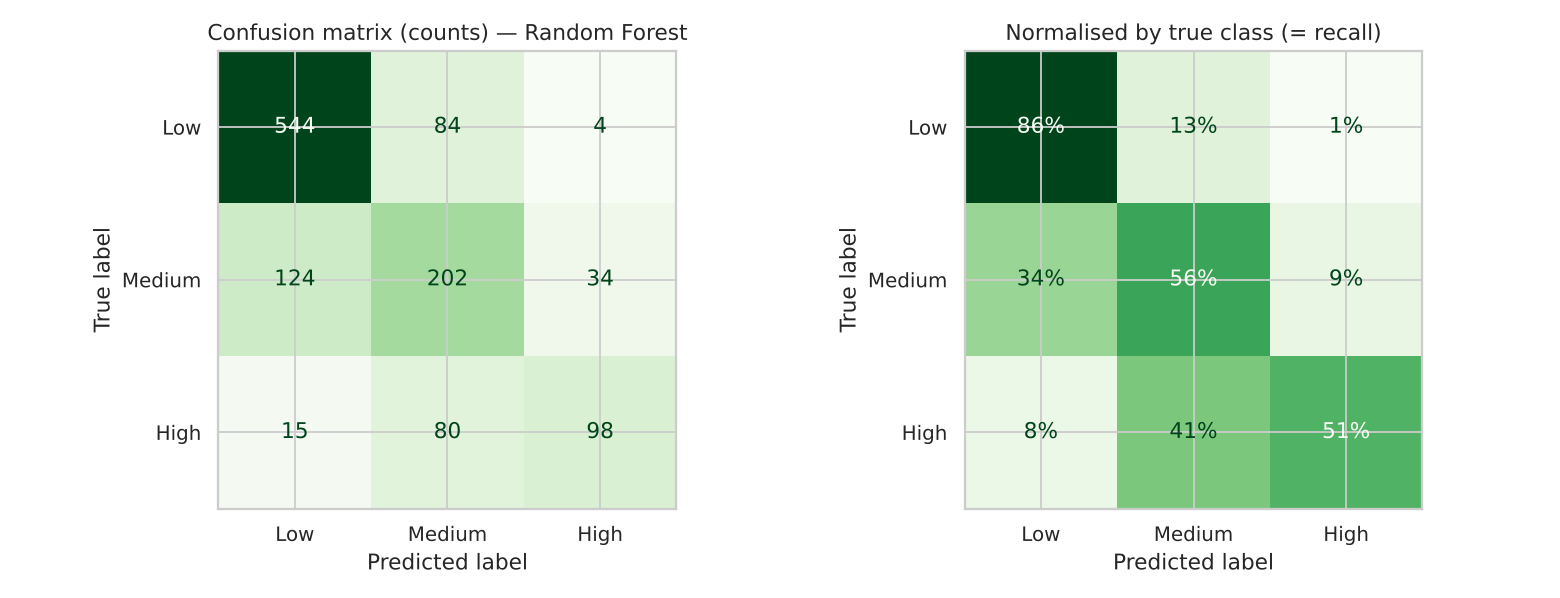

In [26]:
cm = confusion_matrix(y_te, p_te, labels=P.WASTE_LEVELS)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
ConfusionMatrixDisplay(cm, display_labels=P.WASTE_LEVELS).plot(ax=ax[0], cmap='Greens', colorbar=False); ax[0].set_title(f'Confusion matrix (counts) — {BEST_CLF}')
ConfusionMatrixDisplay(confusion_matrix(y_te, p_te, labels=P.WASTE_LEVELS, normalize='true'), display_labels=P.WASTE_LEVELS).plot(ax=ax[1], cmap='Greens', colorbar=False, values_format='.0%'); ax[1].set_title('Normalised by true class (= recall)')
save(fig, 'confusion_matrix_waste_level')

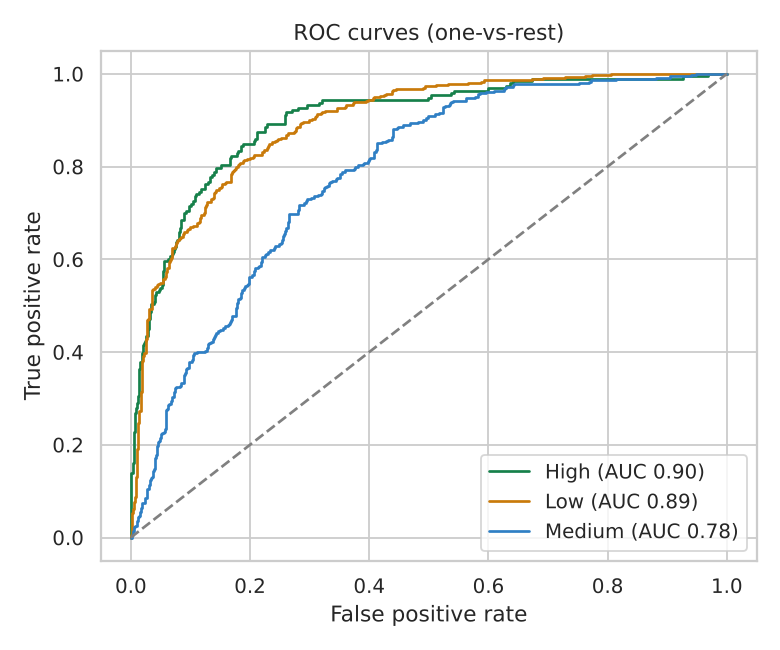

In [27]:
fig, ax = plt.subplots(figsize=(6, 5))
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve((y_te == c).astype(int), proba_te[:, i]); ax.plot(fpr, tpr, label=f'{c} (AUC {roc_auc_score((y_te == c).astype(int), proba_te[:, i]):.2f})')
ax.plot([0, 1], [0, 1], '--', color='gray'); ax.set_xlabel('False positive rate'); ax.set_ylabel('True positive rate'); ax.set_title('ROC curves (one-vs-rest)'); ax.legend()
save(fig, 'roc_waste_level')

In [28]:
# Test results of ALL tuned classifiers (for the comparison table) — each refit on train+val
rows = [{'model': 'Baseline (majority class)', 'accuracy': cls_metrics['baseline_accuracy'], 'precision_macro': precision_score(y_te, [maj]*len(y_te), average='macro', zero_division=0),
         'recall_macro': recall_score(y_te, [maj]*len(y_te), average='macro'), 'f1_macro': f1_score(y_te, [maj]*len(y_te), average='macro'), 'roc_auc': 0.5}]
for name, mk in best_models.items():
    mm = fit_clf(mk(), Xtv, trval.Waste_Level.values, strat_for(name)); pp = mm.predict(Xte_f)
    rows.append({'model': name, 'accuracy': accuracy_score(y_te, pp), 'precision_macro': precision_score(y_te, pp, average='macro'), 'recall_macro': recall_score(y_te, pp, average='macro'),
                 'f1_macro': f1_score(y_te, pp, average='macro'), 'roc_auc': roc_auc_score(y_te, mm.predict_proba(Xte_f), multi_class='ovr', labels=list(mm.classes_))})
    # (XGBoost/LightGBM wrappers return probabilities in the Low/Medium/High order)
clf_test = pd.DataFrame(rows).round(3); clf_test

,model,accuracy,precision_macro,recall_macro,f1_macro,roc_auc
0,Baseline (majority class),0.533,0.178,0.333,0.232,0.500
1,Logistic Regression,0.692,0.680,0.635,0.648,0.856
2,KNN,0.666,0.646,0.560,0.574,0.810
3,Decision Tree,0.697,0.679,0.625,0.642,0.851
4,Random Forest,0.712,0.690,0.643,0.660,0.859
5,Gradient Boosting,0.705,0.679,0.640,0.655,0.856
6,XGBoost (extra),0.709,0.684,0.644,0.659,0.858
7,LightGBM (extra),0.706,0.692,0.635,0.654,0.854


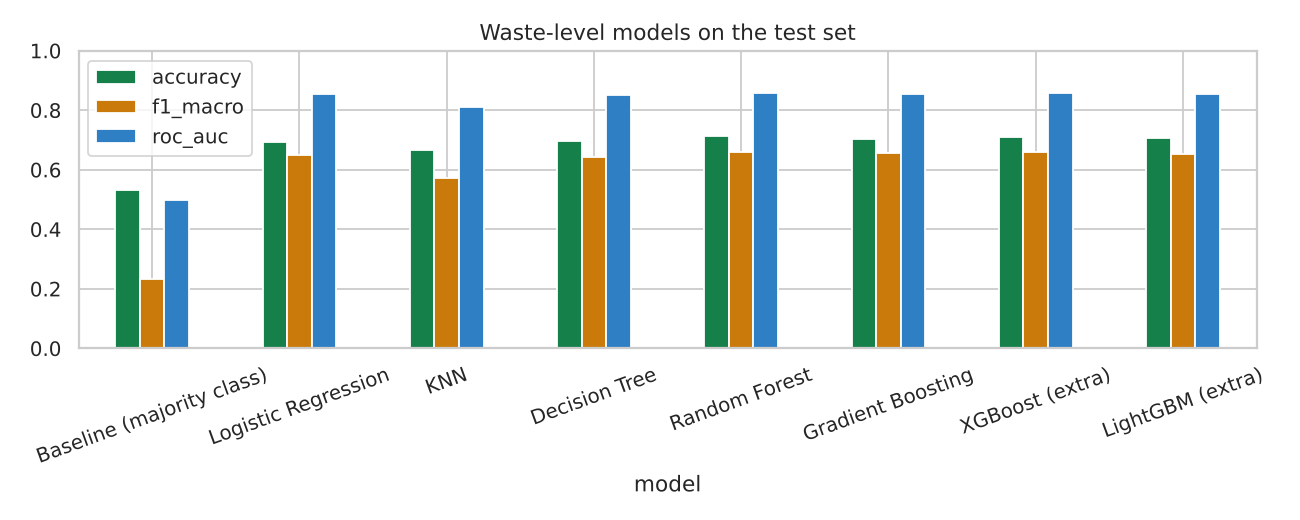

In [29]:
fig, ax = plt.subplots(figsize=(10, 4))
clf_test.set_index('model')[['accuracy', 'f1_macro', 'roc_auc']].plot.bar(ax=ax, rot=20); ax.set_ylim(0, 1); ax.set_title('Waste-level models on the test set')
save(fig, 'model_comparison_waste_level')

In [30]:
# ---- regression metrics (leftover units)
pred_lo = leftover(reg_final, Xte_f, test.Purchase_Quantity.values)
reg_metrics = {'MAE': mean_absolute_error(lo_te, pred_lo), 'RMSE': float(np.sqrt(mean_squared_error(lo_te, pred_lo))), 'R2': r2_score(lo_te, pred_lo),
               'baseline_mean_MAE': mean_absolute_error(lo_te, np.full(len(lo_te), trval.Remaining_Stock.mean())),
               'baseline_rule_MAE': mean_absolute_error(lo_te, Xte_f.Expected_Leftover), 'baseline_rule_R2': r2_score(lo_te, Xte_f.Expected_Leftover)}
lo80 = np.clip(pred_lo + Q10, 0, None); hi80 = pred_lo + Q90
reg_metrics['interval_80_coverage'] = float(np.mean((lo_te >= lo80) & (lo_te <= hi80)))
# "Within ±10 units" — an easy-to-explain accuracy-style number for regression
reg_metrics['within_10_units'] = float(np.mean(np.abs(lo_te - pred_lo) <= 10))
print(json.dumps({k: round(v, 3) for k, v in reg_metrics.items()}, indent=2))
rows = [{'model': 'Baseline: mean leftover', 'MAE': reg_metrics['baseline_mean_MAE'], 'RMSE': np.sqrt(mean_squared_error(lo_te, np.full(len(lo_te), trval.Remaining_Stock.mean()))), 'R2': r2_score(lo_te, np.full(len(lo_te), trval.Remaining_Stock.mean()))},
        {'model': 'Baseline: historical-average rule', 'MAE': reg_metrics['baseline_rule_MAE'], 'RMSE': np.sqrt(mean_squared_error(lo_te, Xte_f.Expected_Leftover)), 'R2': reg_metrics['baseline_rule_R2']}]
for name, m in reg_models.items():
    mm = clone(m).fit(Xtv[ok_tv], d_tv[ok_tv]); pl = leftover(mm, Xte_f, test.Purchase_Quantity.values)
    rows.append({'model': name, 'MAE': mean_absolute_error(lo_te, pl), 'RMSE': np.sqrt(mean_squared_error(lo_te, pl)), 'R2': r2_score(lo_te, pl)})
reg_test = pd.DataFrame(rows).round(3); reg_test

{
  "MAE": 7.818,
  "RMSE": 12.393,
  "R2": 0.915,
  "baseline_mean_MAE": 22.733,
  "baseline_rule_MAE": 7.773,
  "baseline_rule_R2": 0.915,
  "interval_80_coverage": 0.814,
  "within_10_units": 0.711
}


,model,MAE,RMSE,R2
0,Baseline: mean leftover,22.733,42.574,-0.001
1,Baseline: historical-average rule,7.773,12.422,0.915
2,Linear Regression,7.808,12.428,0.915
3,KNN,8.763,13.994,0.892
4,Decision Tree,7.907,12.632,0.912
5,Random Forest,7.879,12.495,0.914
6,Gradient Boosting,7.818,12.393,0.915


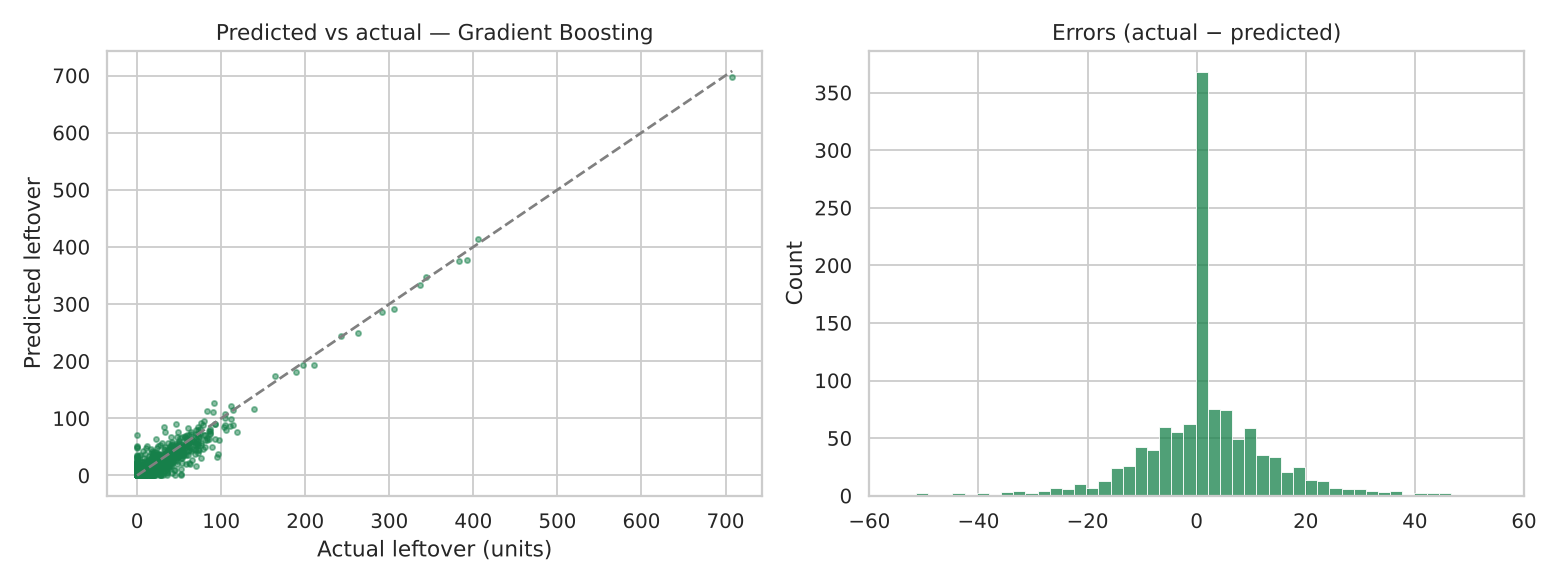

In [31]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(lo_te, pred_lo, s=8, alpha=.5, color='#16804a'); m_ = max(lo_te.max(), pred_lo.max()); ax[0].plot([0, m_], [0, m_], '--', color='gray')
ax[0].set_xlabel('Actual leftover (units)'); ax[0].set_ylabel('Predicted leftover'); ax[0].set_title(f'Predicted vs actual — {BEST_REG}')
sns.histplot(lo_te - pred_lo, bins=60, ax=ax[1]); ax[1].set_title('Errors (actual − predicted)'); ax[1].set_xlim(-60, 60)
save(fig, 'regression_leftover')

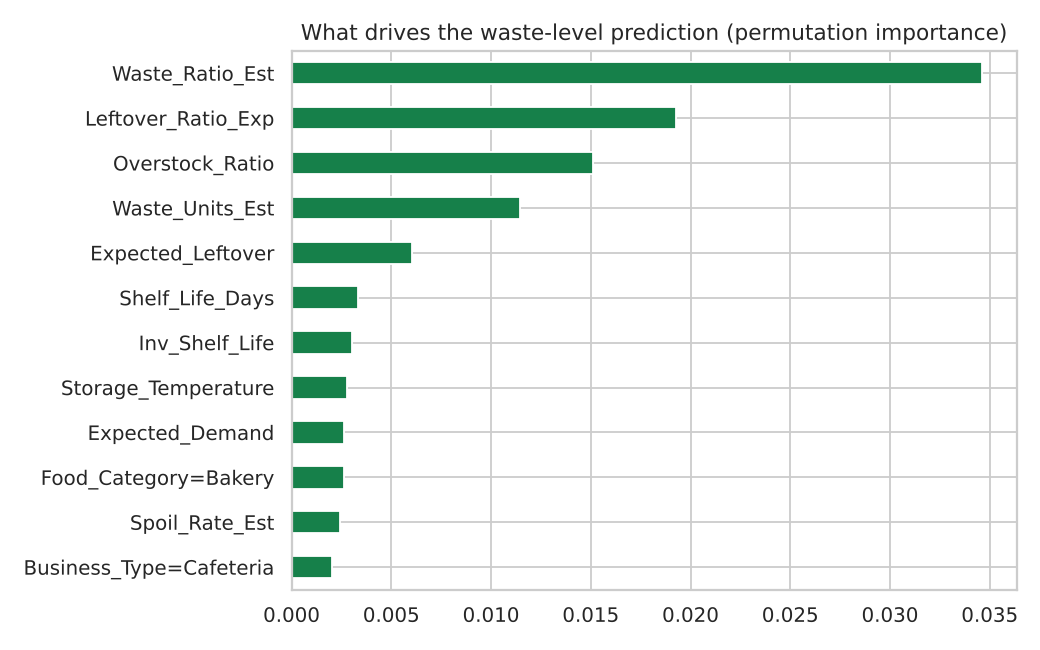

In [32]:
from sklearn.inspection import permutation_importance
pi = permutation_importance(clf_final, Xte_f, y_te, scoring='f1_macro', n_repeats=5, random_state=RS)
imp = pd.Series(pi.importances_mean, index=FEATURES).sort_values(ascending=False).head(12)
fig, ax = plt.subplots(figsize=(8, 5)); imp.plot.barh(ax=ax, color='#16804a'); ax.invert_yaxis(); ax.set_title('What drives the waste-level prediction (permutation importance)')
save(fig, 'feature_importance_waste_level')

## 17. Save the cleaned data, results and the models for the app

In [33]:
df.to_csv('data/processed/food_waste_cleaned.csv', index=False)
for n, s in [('train', train), ('validation', val), ('test', test)]: s.to_csv(f'data/processed/{n}.csv', index=False)
import sys; sys.path.insert(0, '..')
from common.export import export_model
from datetime import datetime, timezone
version = 'waste-v3.' + datetime.now(timezone.utc).strftime('%Y%m%d')
ref = Xtv.values[:5]
bundle = {
  'version': version, 'trained_at': datetime.now(timezone.utc).isoformat(timespec='seconds'),
  'dataset': {'name': 'Kaggle Food Waste dataset', 'rows_raw': int(len(raw)), 'rows_clean': int(len(df)), 'period': f"{df.Date.min().date()} to {df.Date.max().date()}",
              'split': {'train': [str(train.Date.min().date()), str(train.Date.max().date()), len(train)], 'validation': [str(val.Date.min().date()), str(val.Date.max().date()), len(val)], 'test': [str(test.Date.min().date()), str(test.Date.max().date()), len(test)]}},
  'prediction_time': 'morning (before the day starts)', 'leakage_columns_removed': P.LEAKAGE_COLUMNS, 'cleaning': clean_report,
  'artifacts': art_final, 'features': FEATURES,
  'leftover': {'approach': 'predict demand, leftover = max(0, purchase - demand)', 'algorithm': BEST_REG, 'model': export_model(reg_final, ref),
               'interval': {'level': 0.8, 'q_low': float(Q10), 'q_high': float(Q90)}, 'test': reg_metrics, 'comparison_test': reg_test.to_dict('records'), 'comparison_val': reg_val.to_dict('records')},
  'waste_level': {'algorithm': BEST_CLF, 'imbalance_strategy': strat_for(BEST_CLF), 'model': export_model(clf_final, ref), 'labels': P.WASTE_LEVELS, 'classes': classes,
                  'test': cls_metrics, 'confusion_matrix': cm.tolist(), 'report': classification_report(y_te, p_te, labels=P.WASTE_LEVELS, output_dict=True),
                  'comparison_test': clf_test.to_dict('records'), 'comparison_val': clf_val.to_dict('records'), 'imbalance_comparison': imb.to_dict('records'),
                  'feature_importance': imp.round(4).to_dict()},
}
json.dump(bundle, open('../../lib/model/waste-models.json', 'w'), separators=(',', ':'), default=float)
# Golden vectors: raw morning inputs + Python predictions, used to check the TypeScript implementation.
g = test.sample(30, random_state=1)
gold = [{'date': str(r.Date.date()), 'business_type': r.Business_Type, 'food_category': r.Food_Category, 'purchase_quantity': float(r.Purchase_Quantity),
         'shelf_life_days': None if pd.isna(r.Shelf_Life_Days) else float(r.Shelf_Life_Days), 'storage_temperature': None if pd.isna(r.Storage_Temperature) else float(r.Storage_Temperature),
         'promotion': int(r.Promotion), 'weather': None if pd.isna(r.Weather) else r.Weather} for r in g.itertuples()]
Xg = P.build_features(g, art_final)[FEATURES]
json.dump({'inputs': gold, 'features': Xg.round(6).values.tolist(), 'demand': reg_final.predict(Xg).round(5).tolist(), 'proba': clf_final.predict_proba(Xg).round(6).tolist(), 'classes': classes},
          open('../../lib/model/waste-golden.json', 'w'))
summary = {'leftover_regression': {k: round(v, 3) for k, v in reg_metrics.items()}, 'waste_level_classification': {k: round(v, 3) for k, v in cls_metrics.items()},
           'selected': {'leftover': BEST_REG, 'waste_level': BEST_CLF}}
json.dump(summary, open('reports/metrics_summary.json', 'w'), indent=2)
print(json.dumps(summary, indent=2))

{
  "leftover_regression": {
    "MAE": 7.818,
    "RMSE": 12.393,
    "R2": 0.915,
    "baseline_mean_MAE": 22.733,
    "baseline_rule_MAE": 7.773,
    "baseline_rule_R2": 0.915,
    "interval_80_coverage": 0.814,
    "within_10_units": 0.711
  },
  "waste_level_classification": {
    "accuracy": 0.712,
    "precision_macro": 0.69,
    "recall_macro": 0.643,
    "f1_macro": 0.66,
    "precision_weighted": 0.71,
    "recall_weighted": 0.712,
    "f1_weighted": 0.707,
    "roc_auc_ovr_macro": 0.859,
    "baseline_accuracy": 0.533
  },
  "selected": {
    "leftover": "Gradient Boosting",
    "waste_level": "Random Forest"
  }
}


## 18. Conclusion
* The dataset needed: type conversion, logical demand recovery, per-category imputation, leakage removal and class-imbalance handling.
* **Version 3 (accuracy improvement):** spoilage features (how much leftover food usually spoils, by category × shelf life, temperature and weather), model choice by **accuracy over 5 rolling time periods** instead of one validation period, no oversampling, and a wider hyper-parameter search (XGBoost and LightGBM also tried). Day-to-day history (lag) features were tested and rejected: the data has no day-to-day pattern (autocorrelation ≈ 0).
* **Leftover amount:** the AI model reaches the noise floor of this data; it is compared honestly against a strong historical-average rule.
* **Waste level:** clearly better than guessing the majority class; most confusion is between neighbouring levels (Low↔Medium, Medium↔High), which is expected because the labels overlap in the raw data.
* The models are exported to `lib/model/waste-models.json` and run inside the FoodSphere AI app. Predictions are always shown as **estimates**.